In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score

In [23]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
df = pd.read_csv("diabetes_binary_classification_data.csv")
df.drop_duplicates()

df.info()
print(df.dtypes.value_counts())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.139333,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,0.811420,0.056197,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875
std,0.346294,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,0.391175,0.230302,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000
75%,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,1.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


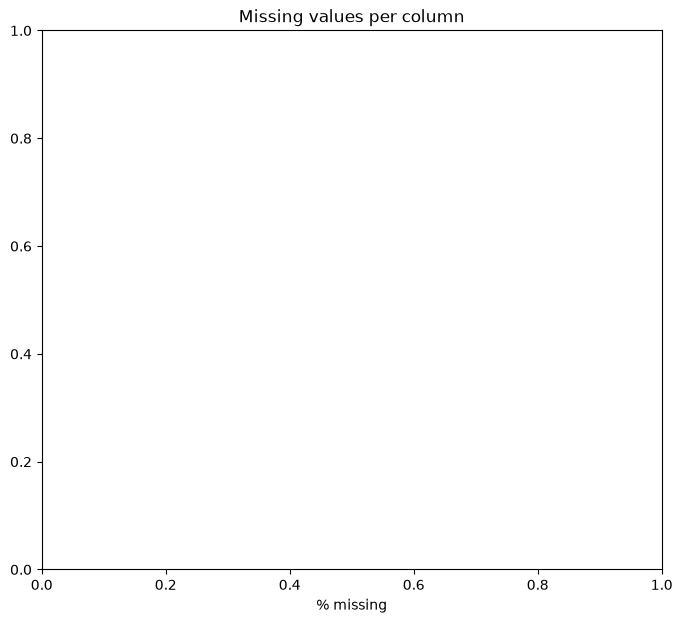

In [24]:
missing = df.isna().mean().mul(100).sort_values(ascending=True)
missing = missing[missing > 0]

plt.figure(figsize=(8, 7))
sns.barplot(x=missing.values, y=missing.index, color="steelblue")
plt.xlabel("% missing")
plt.title("Missing values per column")
plt.show()

No missing data :)

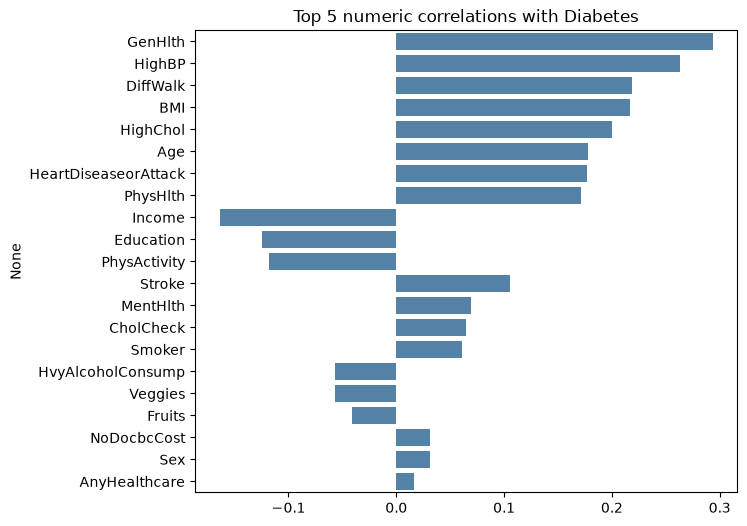

In [25]:
corr = df.corr(numeric_only=True)["Diabetes_binary"].drop("Diabetes_binary")
top = corr.reindex(corr.abs().sort_values(ascending=False).index)[:22]


plt.figure(figsize=(7, 6))
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.title("Top 5 numeric correlations with Diabetes")
plt.show()

Preprocssing

In [26]:
X = df.drop(columns=["Diabetes_binary"])
y = df["Diabetes_binary"]

categories_binary = ["HighBP","HighChol","CholCheck","Smoker","Stroke","HeartDiseaseorAttack",
                     "PhysActivity","Fruits","Veggies","HvyAlcoholConsump",
                     "AnyHealthcare","NoDocbcCost","DiffWalk","Sex"]
for i in categories_binary:
    X[i] = X[i].astype(str) #Catagory not a number

categories = ["MentHlth","PhysHlth","Age","Education","Income"]
for i in categories:
    X[i] = X[i].astype(str) #Catagory not a number

X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=0.8,random_state=42)

Training

In [27]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regression": DecisionTreeRegressor(random_state=42),
    "Random Forest Regression": RandomForestRegressor(random_state=42),
}

In [28]:

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Test RMSE": root_mean_squared_error(y_test, pred),
        "Test R²": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results).round(3)
print(results_df)

                      Model  Test RMSE  Test R²
0         Linear Regression      0.316    0.163
1  Decision Tree Regression      0.451   -0.714
2  Random Forest Regression      0.326    0.105
